# 02 · Meaningful capability compatibility
Improve the previously constant content score using actual training participation.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if str(ROOT.parent) not in sys.path: sys.path.insert(0,str(ROOT.parent))
from ml.src.preprocessing import load_data, read_json, save_json
from ml.src.evaluation import evaluate, feature_groups
from ml.src.notebook_helpers import table, metric_row, chart
from IPython.display import display, Code
import matplotlib.pyplot as plt
%matplotlib inline


A worker profile is a vector of `log(1 + training participation count)` by capability. A task is a one-hot capability vector (or multi-hot requirements). The score is cosine similarity in [0,1]. It measures relevant experience distribution, not certified skill or actual KYC expertise. A worker with no training participation receives zero compatibility. No success labels or synthetic locations are used by CBF.

def score(profile, required_capabilities):
    required = set(required_capabilities)
    if not required or not profile:
        return 0.0
    # Cosine similarity of log participation counts and multi-hot task requirements.
    vector = {c: math.log1p(n) for c, n in profile.items()}
    norm = math.sqrt(sum(v*v for v in vector.values()))
    return sum(vector.get(c, 0) for c in required) / (norm * math.sqrt(len(required))) if norm else 0.0

Worker,Training capability counts,Compatibility with 50
105,{'53': 789},0.0
282,{'53': 449},0.0
57,{'53': 1109},0.0
59,{'53': 864},0.0
61,{'53': 820},0.0
252,"{'53': 657, '69': 12}",0.0


Model,Top-1 %,P@3 %,R@3 %,MAP@3 %,Full MAP %,NDCG@3 %
Content / validation,70.218,73.34,59.863,66.153,79.421,72.719


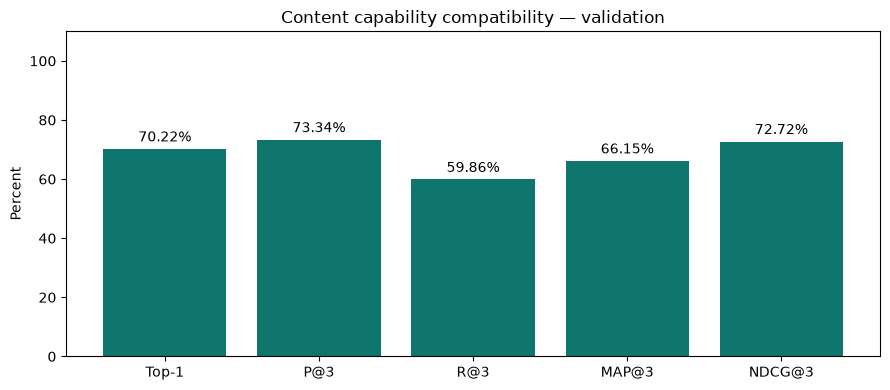

In [2]:
from ml.src.content_based import build_profiles, score
display(Code(inspect.getsource(score),language='python'))
profiles=read_json('models/netease/capability_profiles.json')
table([{'Worker':w,'Training capability counts':p,'Compatibility with 50':round(score(p,['50']),4)} for w,p in list(profiles.items())[:6]])
groups,splits=load_data(); features=read_json('models/netease/features.json')
validation=feature_groups(groups,splits['validation'],features)
result=evaluate(validation,(1,0,0),3)
table([metric_row('Content / validation',result)])
chart('Content capability compatibility — validation',result,'content.png')